In [4]:
import pandas as pd
import matplotlib.pyplot as plt

print("Tutto funziona")

Tutto funziona


In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import pandas_datareader.data as web
import datetime

start = datetime.datetime(2000, 1, 1)
end = datetime.datetime(2023, 12, 31)

print("Librerie caricate correttamente")

Librerie caricate correttamente


In [6]:
from pandas_datareader import wb

paesi = ['IT', 'DE', 'FR', 'ES', 'GR']

pil = wb.download(indicator='NY.GDP.MKTP.KD.ZG', 
                  country=paesi, 
                  start=2000, 
                  end=2023)

pil.columns = ['PIL_crescita']

print(pil.head(10))

              PIL_crescita
country year              
Germany 2023     -0.869648
        2022      1.809258
        2021      3.910000
        2020     -4.131914
        2019      0.977735
        2018      1.135696
        2017      2.797907
        2016      2.222222
        2015      1.663006
        2014      2.180186


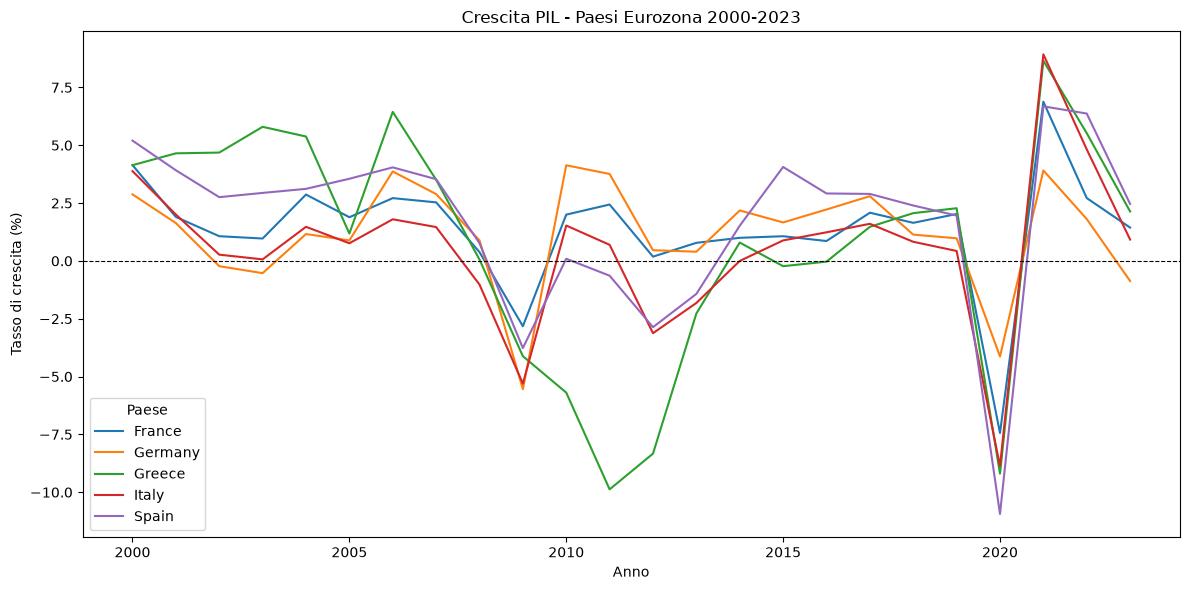

In [7]:
pil_unstack = pil.unstack(level=0)['PIL_crescita']

pil_unstack.plot(figsize=(12,6), 
                 title='Crescita PIL - Paesi Eurozona 2000-2023')

plt.axhline(y=0, color='black', linewidth=0.8, linestyle='--')
plt.ylabel('Tasso di crescita (%)')
plt.xlabel('Anno')
plt.legend(title='Paese')
plt.tight_layout()
plt.show()

In [8]:
from pandas_datareader import wb

paesi = ['IT', 'DE', 'FR', 'ES', 'GR']

disoccupazione = wb.download(indicator='SL.UEM.TOTL.ZS', 
                            country=paesi, 
                            start=2000, 
                            end=2023)
disoccupazione.columns = ['Disoccupazione']
print(disoccupazione.head(10))

              Disoccupazione
country year                
Germany 2023           3.071
        2022           3.137
        2021           3.594
        2020           3.881
        2019           3.163
        2018           3.384
        2017           3.781
        2016           4.104
        2015           4.612
        2014           4.979


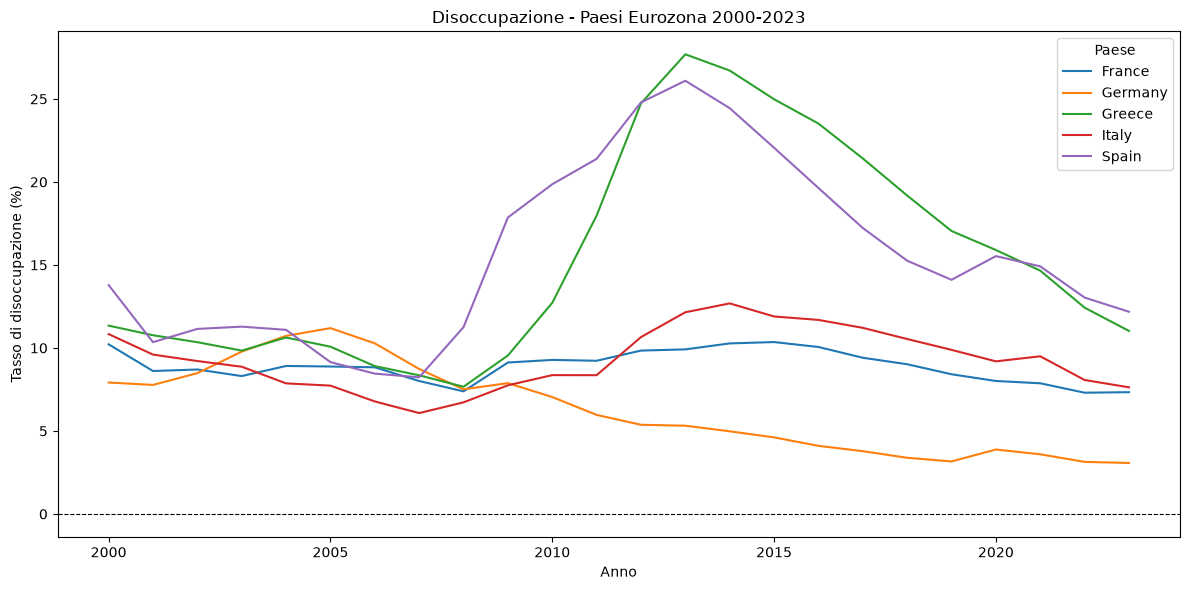

In [9]:
disoccupazione_unstack = disoccupazione.unstack(level=0)['Disoccupazione']

disoccupazione_unstack.plot(figsize=(12,6), 
                            title='Disoccupazione - Paesi Eurozona 2000-2023')

plt.axhline(y=0, color='black', linewidth=0.8, linestyle='--')
plt.ylabel('Tasso di disoccupazione (%)')
plt.xlabel('Anno')
plt.legend(title='Paese')
plt.tight_layout()
plt.show()

In [10]:
from pandas_datareader import wb

paesi = ['IT', 'DE', 'FR', 'ES', 'GR']

inflazione = wb.download(indicator='FP.CPI.TOTL.ZG', 
                         country=paesi, 
                         start=2000, 
                         end=2023)
inflazione.columns = ['Inflazione']
print(inflazione.head(10))

              Inflazione
country year            
Germany 2023    5.946437
        2022    6.872574
        2021    3.066667
        2020    0.144878
        2019    1.445660
        2018    1.732169
        2017    1.509495
        2016    0.491747
        2015    0.514426
        2014    0.906794


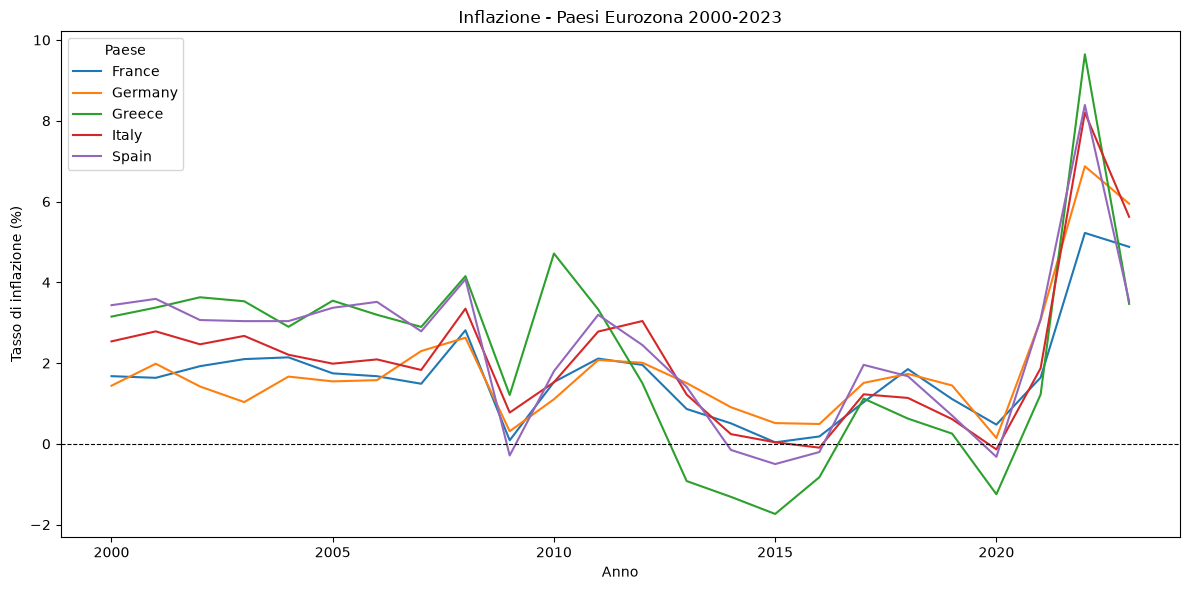

In [11]:
inflazione_unstack = inflazione.unstack(level=0)['Inflazione']

inflazione_unstack.plot(figsize=(12,6), 
                            title='Inflazione - Paesi Eurozona 2000-2023')

plt.axhline(y=0, color='black', linewidth=0.8, linestyle='--')
plt.ylabel('Tasso di inflazione (%)')
plt.xlabel('Anno')
plt.legend(title='Paese')
plt.tight_layout()
plt.show()

In [12]:
pil_stats = pil_unstack.describe().loc[['mean', 'std', 'min', 'max']].add_prefix('PIL_')
print(pil_stats)

country  PIL_France  PIL_Germany  PIL_Greece  PIL_Italy  PIL_Spain
mean       1.388157     1.181204    0.791981   0.560961   1.730890
std        2.528748     2.333808    5.072103   3.317242   3.727635
min       -7.440646    -5.544555   -9.876779  -8.868221 -10.940071
max        6.882338     4.134638    8.654498   8.931062   6.683144


In [14]:
pil_stats = pil_unstack.describe().loc[['mean', 'std', 'min', 'max']].add_prefix('PIL_')
disoccupazione_stats = disoccupazione_unstack.describe().loc[['mean', 'std', 'min', 'max']].add_prefix('Disoccupazione_')
inflazione_stats = inflazione_unstack.describe().loc[['mean', 'std', 'min', 'max']].add_prefix('Inflazione_')
pd.concat([pil_stats, disoccupazione_stats, inflazione_stats], axis=1)

country,PIL_France,PIL_Germany,PIL_Greece,PIL_Italy,PIL_Spain,Disoccupazione_France,Disoccupazione_Germany,Disoccupazione_Greece,Disoccupazione_Italy,Disoccupazione_Spain,Inflazione_France,Inflazione_Germany,Inflazione_Greece,Inflazione_Italy,Inflazione_Spain
mean,1.388157,1.181204,0.791981,0.560961,1.730890,8.886875,6.319667,15.309000,9.301875,15.545833,1.695181,1.884656,2.142416,2.082671,2.360265
std,2.528748,2.333808,5.072103,3.317242,3.727635,0.937452,2.646324,6.428846,1.846933,5.384246,1.260950,1.565039,2.525461,1.842657,1.960700
min,-7.440646,-5.544555,-9.876779,-8.868221,-10.940071,7.303000,3.071000,7.664000,6.076000,8.232000,0.037514,0.144878,-1.735888,-0.137708,-0.500366
max,6.882338,4.134638,8.654498,8.931062,6.683144,10.354000,11.193000,27.686000,12.683000,26.094000,5.222367,6.872574,9.645260,8.201290,8.390576


In [27]:
pil_crisis = pil_unstack.loc['2008':'2013']
disoccupazione_crisis = disoccupazione_unstack.loc['2008':'2013']
inflazione_crisis = inflazione_unstack.loc['2008':'2013']
pil_crisis_stats = pil_crisis.describe().loc[['mean', 'std', 'min', 'max']].add_prefix('PIL_')
disoccupazione_crisis_stats = disoccupazione_crisis.describe().loc[['mean', 'std', 'min', 'max']].add_prefix('Disoccupazione_')
inflazione_crisis_stats = inflazione_crisis.describe().loc[['mean', 'std', 'min', 'max']].add_prefix('Inflazione_')
crisis_stats = pd.concat([pil_crisis_stats, disoccupazione_crisis_stats, inflazione_crisis_stats], axis=1)
(crisis_stats)


country,PIL_France,PIL_Germany,PIL_Greece,PIL_Italy,PIL_Spain,Disoccupazione_France,Disoccupazione_Germany,Disoccupazione_Greece,Disoccupazione_Italy,Disoccupazione_Spain,Inflazione_France,Inflazione_Germany,Inflazione_Greece,Inflazione_Italy,Inflazione_Spain
mean,0.493185,0.682744,-5.039262,-1.507831,-1.306534,9.128167,6.514333,16.719833,8.999667,20.207333,1.560186,1.605552,2.330995,2.115018,2.106368
std,1.857485,3.473431,3.718777,2.507760,1.744114,0.915641,1.111072,8.191272,2.011050,5.345093,0.967767,0.820043,2.121899,1.073857,1.516099
min,-2.824552,-5.544555,-9.876779,-5.305154,-3.768133,7.386000,5.316000,7.664000,6.723000,11.254000,0.087620,0.312739,-0.921269,0.774768,-0.287813
max,2.437577,4.134638,0.057474,1.529106,0.767166,9.913000,7.880000,27.686000,12.149000,26.094000,2.812862,2.628380,4.712989,3.347833,4.075343
